# 实验二 图像灰度变换与直方图均衡

## 实验1 图像阈值化

**实验要求**：采用固定阈值方法，编程实现cameraman.tif图像二值化

**实验说明**：

1. 手动实现阈值变换。
2. 要求分别实现三种阈值（50,100,200，小于阈值置0，反之亦然）。
3. 需要将原图与处理后的图像，分左右同时显示或保存。
4. 利用图像拷贝等操作将原图与处理后的图像拷贝至大图像 当中，实现同时显示或保存。

In [23]:
import cv2 as cv
import numpy as np
import sys
import os
import matplotlib.pyplot as plt # jupyter 无法用imshow直接显示图片，因此用 plt 代替

os.makedirs("Exp2_figs", exist_ok=True)

# ============================================================================
# 以下 4 个工具函数（show / to_uint8 / _pad / concat）由 AI 生成
#   show()   : 用 plt.subplot 分格预览多张图，返回 None，不能存盘
#   concat() : 把多张图真正拼成一个 ndarray，可 imshow 显示也可 imwrite 存盘
#              实验要求里的"拷贝至大图像"就是用 concat() 实现
# ============================================================================


# AI 给定的图像拼接代码
def show(imgs, titles, cols=None, size=4):
    """imgs: ndarray 列表（BGR 三通道 或 单通道都行）"""
    n = len(imgs); cols = cols or n
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(size*cols, size*rows))
    for i, (im, t) in enumerate(zip(imgs, titles), 1):
        plt.subplot(rows, cols, i)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray', vmin=0, vmax=255)   # vmin/vmax 别省
        else:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(t); plt.axis('off')
    plt.tight_layout(); plt.show()


# AI 生成：安全转 uint8，防止 float 越界 / cv.imwrite 静默截断
def to_uint8(im):
    """把 float / 其它整型安全转成 uint8（超范围先 clip，防止回绕/截断）"""
    if im.dtype == np.uint8:
        return im
    return np.clip(im, 0, 255).astype(np.uint8)


# AI 生成：把图居中补到指定尺寸（concat 内部用）
def _pad(im, H, W, fill=0):
    """把 im 居中补到 (H, W)；尺寸已达标就原样返回"""
    h, w = im.shape[:2]
    if (h, w) == (H, W):
        return im
    canvas = np.full((H, W) + im.shape[2:], fill, np.uint8)   # shape[2:] 兼容灰度/彩色
    y0, x0 = (H - h) // 2, (W - w) // 2
    canvas[y0:y0+h, x0:x0+w] = im
    return canvas


# AI 生成：多图拼接成一张大图（对应实验要求 3、4）
def concat(imgs, axis=1, gap=0, gap_color=255, labels=None, fill=0):
    """把多张图拼接成一张 ndarray，可直接 plt.imshow / cv.imwrite

    imgs      : ndarray 列表，单通道灰度和三通道 BGR 可以混着传
    axis      : 1 = 左右拼接（默认），0 = 上下拼接
    gap       : 图与图之间插入的分隔条宽度（像素），0 表示紧贴
    gap_color : 分隔条颜色（灰度图传 int，彩色图传 (B,G,R) 或 int）
    labels    : 图注列表（可选，cv.putText 画在左上角，只支持 ASCII 字符！）
    fill      : 尺寸不一致时补边的灰度值，默认 0（黑）
    """
    if not imgs:
        raise ValueError("imgs 不能为空")

    imgs = [to_uint8(im) for im in imgs]

    # 只要有彩色图，就把灰度图升成 BGR，否则 np.concatenate 会因通道数不同失败
    if any(im.ndim == 3 for im in imgs):
        imgs = [im if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2BGR)
                for im in imgs]

    # 尺寸不一致时补边（axis=1 只需统一高，axis=0 只需统一宽）
    H = max(im.shape[0] for im in imgs)
    W = max(im.shape[1] for im in imgs)
    if len({im.shape[:2] for im in imgs}) > 1:
        print(f"[concat] 尺寸不一致，已补边到 H={H}, W={W}")
    if axis == 1:
        imgs = [_pad(im, H, im.shape[1], fill) for im in imgs]
    else:
        imgs = [_pad(im, im.shape[0], W, fill) for im in imgs]

    if labels:
        for im, t in zip(imgs, labels):
            t = str(t)
            if not t.isascii():
                print(f"[concat] 警告: '{t}' 含非 ASCII 字符，cv.putText 会画成 '???'")
            light = 255 if im.ndim == 2 else (255, 255, 255)
            dark  = 0   if im.ndim == 2 else (0, 0, 0)
            org = (10, 34)
            cv.putText(im, t, org, cv.FONT_HERSHEY_SIMPLEX, 0.9, dark,  4, cv.LINE_AA)
            cv.putText(im, t, org, cv.FONT_HERSHEY_SIMPLEX, 0.9, light, 1, cv.LINE_AA)

    parts = []
    for i, im in enumerate(imgs):
        if i > 0 and gap > 0:
            shp = (im.shape[0], gap) if axis == 1 else (gap, im.shape[1])
            parts.append(np.full(shp + im.shape[2:], gap_color, np.uint8))
        parts.append(im)
    return np.concatenate(parts, axis=axis)

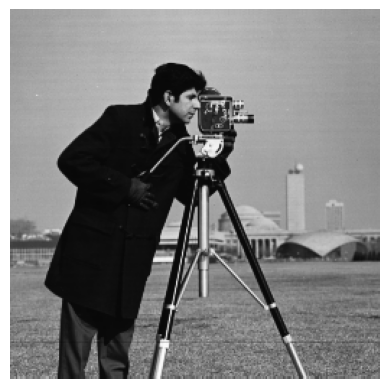

In [24]:

cameraman = cv.imread("testimgs/cameraman.tif") # 读取图片
if cameraman is None:
    sys.exit("Could not read the image.")
# cv.imshow("Display window", img) # jupyter 使用时注释掉这一行，换成下面的 plt
plt.imshow(cv.cvtColor(cameraman, cv.COLOR_BGR2RGB))   # 注意 BGR→RGB
plt.axis("off")
plt.show()

In [25]:
cameraman_gray = cv.cvtColor(cameraman, cv.COLOR_BGR2GRAY) # 转为灰度图

# 生成掩膜 mask
T1 = 50
T2 = 100
T3 = 200

mask1 = cameraman_gray > T1
mask2 = cameraman_gray > T2
mask3 = cameraman_gray > T3

# 二值转换+类型变换
out1 = np.where(mask1, 255, 0).astype(np.uint8)
out2 = np.where(mask2, 255, 0).astype(np.uint8)
out3 = np.where(mask3, 255, 0).astype(np.uint8)

阈值 T = 50：左 = 原图，右 = 二值化结果


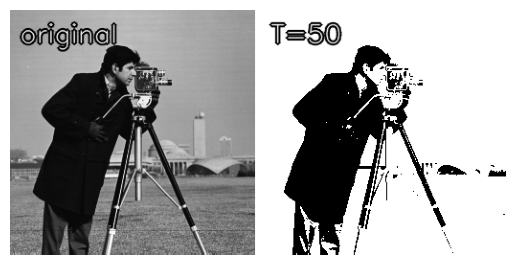

阈值 T = 100：左 = 原图，右 = 二值化结果


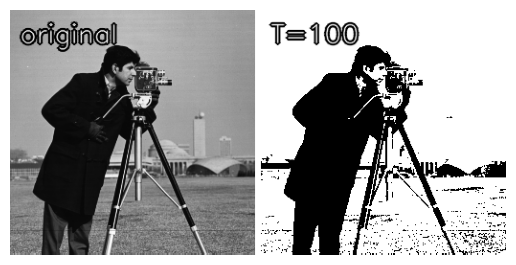

阈值 T = 200：左 = 原图，右 = 二值化结果


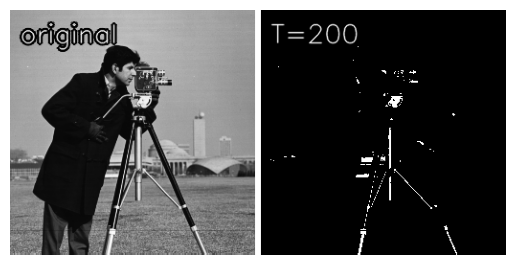

In [26]:
for out, T in zip([out1, out2, out3], [T1, T2, T3]):
    canvas = concat([cameraman_gray, out], gap=6, labels=["original", f"T={T}"])

    print(f"阈值 T = {T}：左 = 原图，右 = 二值化结果")
    plt.imshow(canvas, cmap='gray', vmin=0, vmax=255)
    plt.axis("off")
    plt.show()

    cv.imwrite(f"Exp2_figs/cameraman_T{T}.png", canvas)   # 同时保存

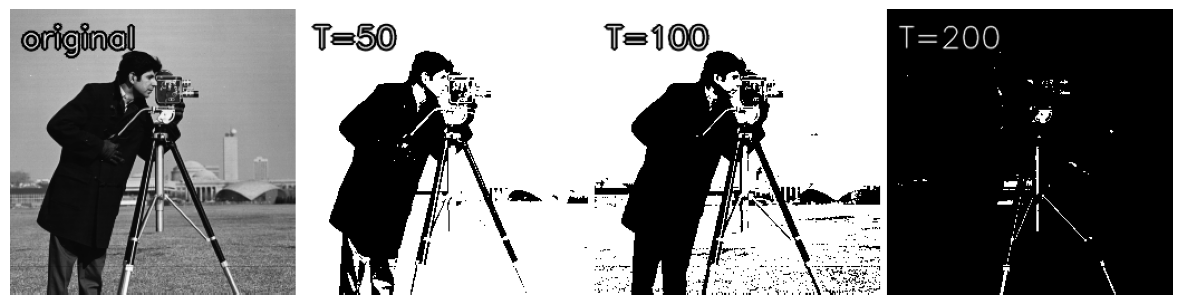

汇总图尺寸: (256, 1042)  dtype: uint8


In [27]:
summary = concat([cameraman_gray, out1, out2, out3], gap=6,
                 labels=["original", f"T={T1}", f"T={T2}", f"T={T3}"])

plt.figure(figsize=(15, 4))
plt.imshow(summary, cmap='gray', vmin=0, vmax=255)
plt.axis("off")
plt.show()

cv.imwrite("Exp2_figs/cameraman_thresholds.png", summary)
print("汇总图尺寸:", summary.shape, " dtype:", summary.dtype)

## 实验2 对比度变换

**实验要求**：采用线性变换方法，编程实现 barbara.tif 图像的对比度调整

**实验说明**：

1. 选用合适的线性变换函数，将图像的对比度降低与提高。
2. 需要将原图与处理后的图像，分左右同时显示或保存。
3. 利用图像拷贝等操作将原图与处理后的图像拷贝至大图像当中，实现同时显示或保存。

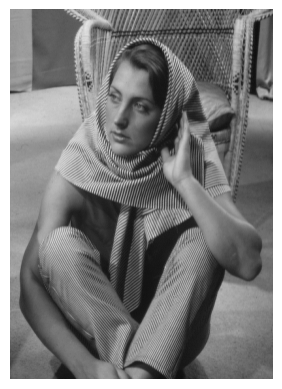

原图灰度范围： 4 ~ 247


In [28]:
barbara = cv.imread("testimgs/barbara.tif")     # 读取图片
if barbara is None:
    sys.exit("Could not read the image.")

barbara_gray = cv.cvtColor(barbara, cv.COLOR_BGR2GRAY)   # 转为灰度图

plt.imshow(barbara_gray, cmap='gray', vmin=0, vmax=255)
plt.axis("off")
plt.show()

print("原图灰度范围：", barbara_gray.min(), "~", barbara_gray.max())

In [29]:
# 线性变换 s = alpha * r + beta（这里 beta = 0，只调整对比度）
#   alpha < 1：对比度降低，灰度值向中间靠拢
#   alpha > 1：对比度提高，灰度值向两端拉开
alpha_low  = 0.5
alpha_high = 1.5

barbara_low  = to_uint8(barbara_gray.astype(np.float32) * alpha_low)
barbara_high = to_uint8(barbara_gray.astype(np.float32) * alpha_high)

print("降低对比度后灰度范围：", barbara_low.min(), "~", barbara_low.max())
print("提高对比度后灰度范围：", barbara_high.min(), "~", barbara_high.max())

降低对比度后灰度范围： 2 ~ 123
提高对比度后灰度范围： 6 ~ 255


对比度降低（a = 0.5）：左 = 原图，右 = 处理结果


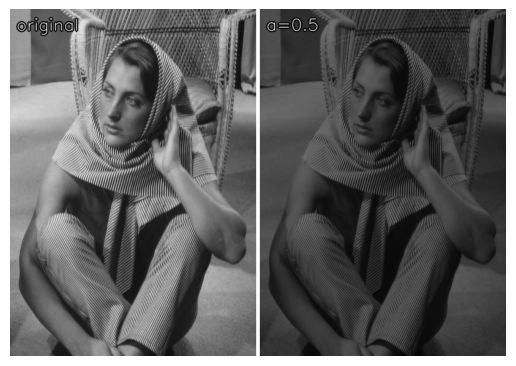

对比度提高（a = 1.5）：左 = 原图，右 = 处理结果


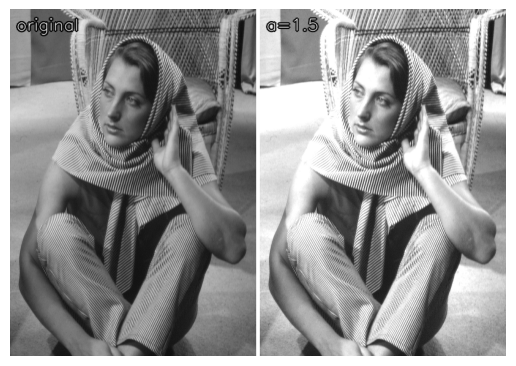

True

In [30]:
canvas_low = concat([barbara_gray, barbara_low], gap=6,
                    labels=["original", f"a={alpha_low}"])
canvas_high = concat([barbara_gray, barbara_high], gap=6,
                     labels=["original", f"a={alpha_high}"])

print(f"对比度降低（a = {alpha_low}）：左 = 原图，右 = 处理结果")
plt.imshow(canvas_low, cmap='gray', vmin=0, vmax=255)
plt.axis("off")
plt.show()
cv.imwrite("Exp2_figs/barbara_contrast_low.png", canvas_low)

print(f"对比度提高（a = {alpha_high}）：左 = 原图，右 = 处理结果")
plt.imshow(canvas_high, cmap='gray', vmin=0, vmax=255)
plt.axis("off")
plt.show()
cv.imwrite("Exp2_figs/barbara_contrast_high.png", canvas_high)

## 实验3 直方图均衡

**实验要求**：编程实现 lenna.tif 彩色图像直方图均衡

**实验说明**：

1. 手动实现直方图均衡。
2. 需要将原图与处理后的图像，分左右同时显示或保存。
3. 在实验报告中对比分析彩色原图与直方图均衡后图像效果。
4. 在实验报告中展示 R,G,B 三通道各个分量直方图均衡前后结果。

In [ ]:
def hist_equalize(gray):
    """直方图均衡函数"""
    hist = np.bincount(gray.ravel(), minlength=256)
    cdf = np.cumsum(hist)
    lut = np.round(cdf * 255 / gray.size).astype(np.uint8)
    return lut[gray]


lenna = cv.imread("testimgs/lenna.tif")
b, g, r = cv.split(lenna)          # OpenCV 通道顺序是 B, G, R

b_eq, g_eq, r_eq = hist_equalize(b), hist_equalize(g), hist_equalize(r)
lenna_eq = cv.merge([b_eq, g_eq, r_eq])

print("原图:", lenna.shape, " 均衡后:", lenna_eq.shape)

原图: (512, 512, 3)  均衡后: (512, 512, 3)


[ WARN:0@744.516] global grfmt_tiff.cpp:122 TIFF_Warning TIFFFetchNormalTag: ASCII value for tag "ImageDescription" does not end in null byte. Forcing it to be null


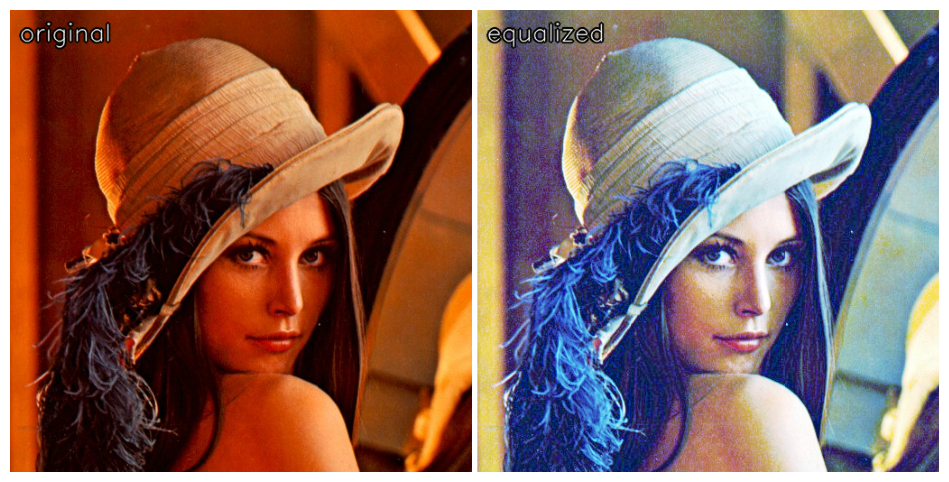

True

In [32]:
canvas = concat([lenna, lenna_eq], gap=6, labels=["original", "equalized"])

plt.figure(figsize=(12, 6))
plt.imshow(cv.cvtColor(canvas, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp2_figs/lenna_histeq.png", canvas)

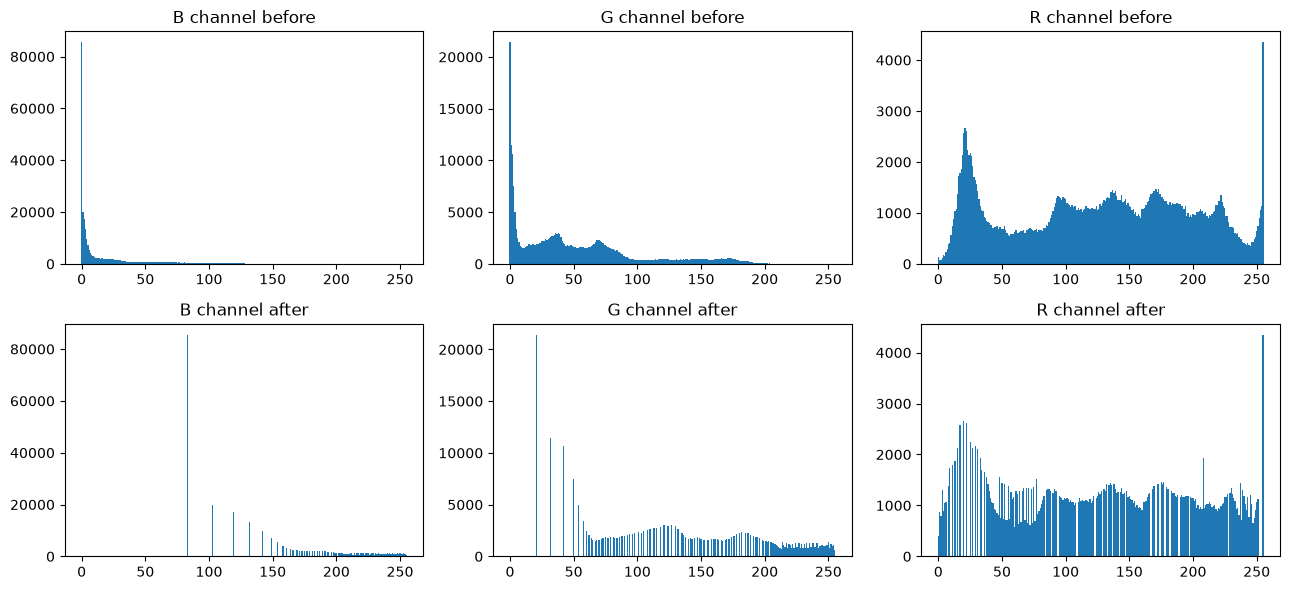

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for i, (before, after, name) in enumerate(zip([b, g, r], [b_eq, g_eq, r_eq], ["B", "G", "R"])):
    axes[0, i].bar(np.arange(256), np.bincount(before.ravel(), minlength=256), width=1)
    axes[0, i].set_title(f"{name} channel before")
    axes[1, i].bar(np.arange(256), np.bincount(after.ravel(), minlength=256), width=1)
    axes[1, i].set_title(f"{name} channel after")

plt.tight_layout()
plt.savefig("Exp2_figs/lenna_histeq_hist.png", dpi=100)
plt.show()

## 实验4 图像白平衡

**实验要求**：编程实现两种图像白平衡算法

**实验说明**：

1. 手动实现白平衡算法，使用 whiteBalance 文件夹中的图像进行测试。
2. 需要将原图与处理后的图像，分左右同时显示或保存。
3. 利用图像拷贝等操作将原图与处理后的图像拷贝至大图像当中，实现同时显示或保存。
4. 在实验报告中对比分析白平衡前后图像效果。

In [34]:
def gray_world(img):
    """灰度世界法：假设 R、G、B 三通道平均灰度趋于同一个值 K"""
    f = img.astype(np.float32)
    avg = f.reshape(-1, 3).mean(axis=0)      # 各通道平均值 (B, G, R)
    K = avg.mean()                           # K = (R + G + B) / 3
    return to_uint8(f * (K / avg))           # 各通道增益 K / avg


def perfect_reflector(img, ratio=0.1):
    """完美反射法：取 R+G+B 最大的 ratio 比例像素作为白点"""
    f = img.astype(np.float32)
    s = f.sum(axis=2)
    T = np.percentile(s, (1 - ratio) * 100)  # 高于 T 的点认为是近似白色
    avg = f[s > T].mean(axis=0)
    return to_uint8(f * (255.0 / avg))

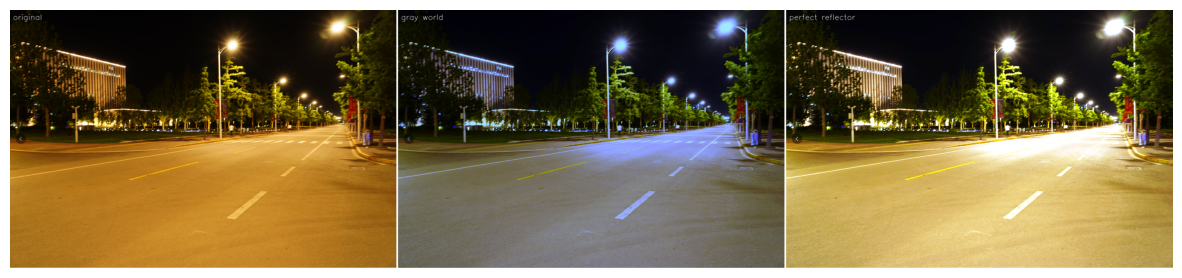

jiedao.png 各通道均值 (B,G,R) 原图 [ 24.1  82.4 118.7] -> 灰度世界 [69.3 74.6 74.6]


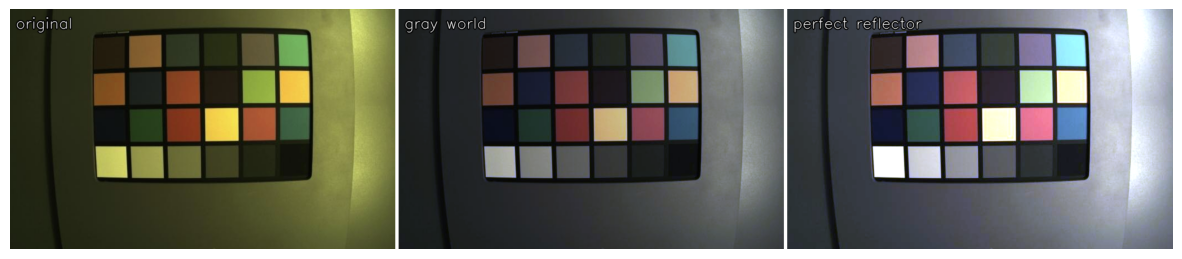

color.png 各通道均值 (B,G,R) 原图 [40.1 78.4 79. ] -> 灰度世界 [65.4 65.4 65.3]


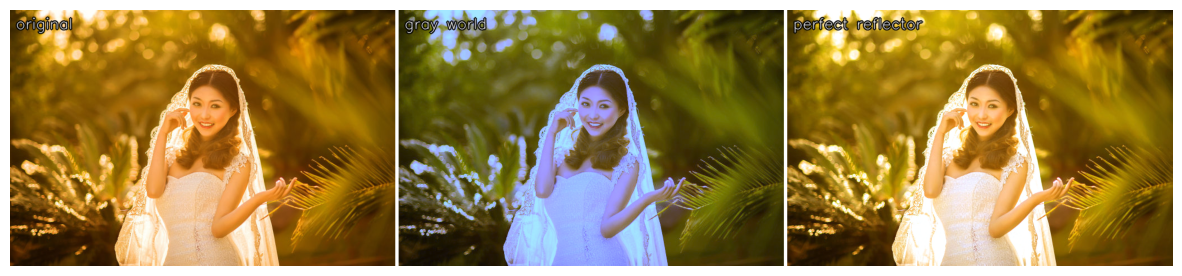

hunsha.jpg 各通道均值 (B,G,R) 原图 [ 37.2 113.6 160.1] -> 灰度世界 [ 70.5 103.1 103.1]


In [35]:
for name in ["jiedao.png", "color.png", "hunsha.jpg"]:
    img = cv.imread(f"testimgs/whiteBalance/{name}")
    gw = gray_world(img)
    pr = perfect_reflector(img)

    canvas = concat([img, gw, pr], gap=6,
                    labels=["original", "gray world", "perfect reflector"])

    plt.figure(figsize=(15, 6))
    plt.imshow(cv.cvtColor(canvas, cv.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    cv.imwrite(f"Exp2_figs/wb_{name.rsplit('.', 1)[0]}.png", canvas)
    print(name, "各通道均值 (B,G,R) 原图", img.reshape(-1, 3).mean(axis=0).round(1),
          "-> 灰度世界", gw.reshape(-1, 3).mean(axis=0).round(1))